# Gontrode spectra variability exploration

Explore existing measurements of spectra from Gontrode.

The aim is to get a feeling of the variability between measurements and trees to help design the field protocol for the new measurements.

In [ ]:
from pyprojroot import here
import polars as pl
from polars import col as c
from pathlib import Path
from plotnine import *

theme_set(theme_bw())

In [ ]:
def load_spectra(spectra_path: Path) -> pl.LazyFrame:
    """
    Load spectra data from a CSV file into a Polars DataFrame.

    Parameters:
    spectra_path (Path): The path to the CSV file containing the spectra data.

    Returns:
    pl.DataFrame: A Polars DataFrame containing the loaded spectra data.
    """
    return (
        pl.scan_csv(
            spectra_path,
            separator="\t",
            has_header=False,
            skip_rows=1,
            schema={"wavelength": pl.Float64, "reflectance": pl.String},
        )
        .with_columns(
            reflectance=c.reflectance.str.strip_chars(" ").cast(pl.Float64),
            file_id=pl.lit(spectra_path.stem),
        )
        .with_columns(
            reflectance=pl.when(c.reflectance.is_between(0, 1))
            .then(c.reflectance)
            .otherwise(pl.lit(None))
        )
    )

In [ ]:
test_spectra_path = here(
    "data/existing/old_spectra/gontrode_asd_23082024/leaves/txt/beuk_123_00000.asd.txt"
)

In [8]:
test_sp = load_spectra(test_spectra_path).collect()
test_sp

wavelength,reflectance,file_id
f64,f64,str
350.0,0.060586,"""beuk_123_00000.asd"""
351.0,0.061804,"""beuk_123_00000.asd"""
352.0,0.065907,"""beuk_123_00000.asd"""
353.0,0.064279,"""beuk_123_00000.asd"""
354.0,0.058733,"""beuk_123_00000.asd"""
…,…,…
2496.0,0.142854,"""beuk_123_00000.asd"""
2497.0,0.143479,"""beuk_123_00000.asd"""
2498.0,0.139495,"""beuk_123_00000.asd"""


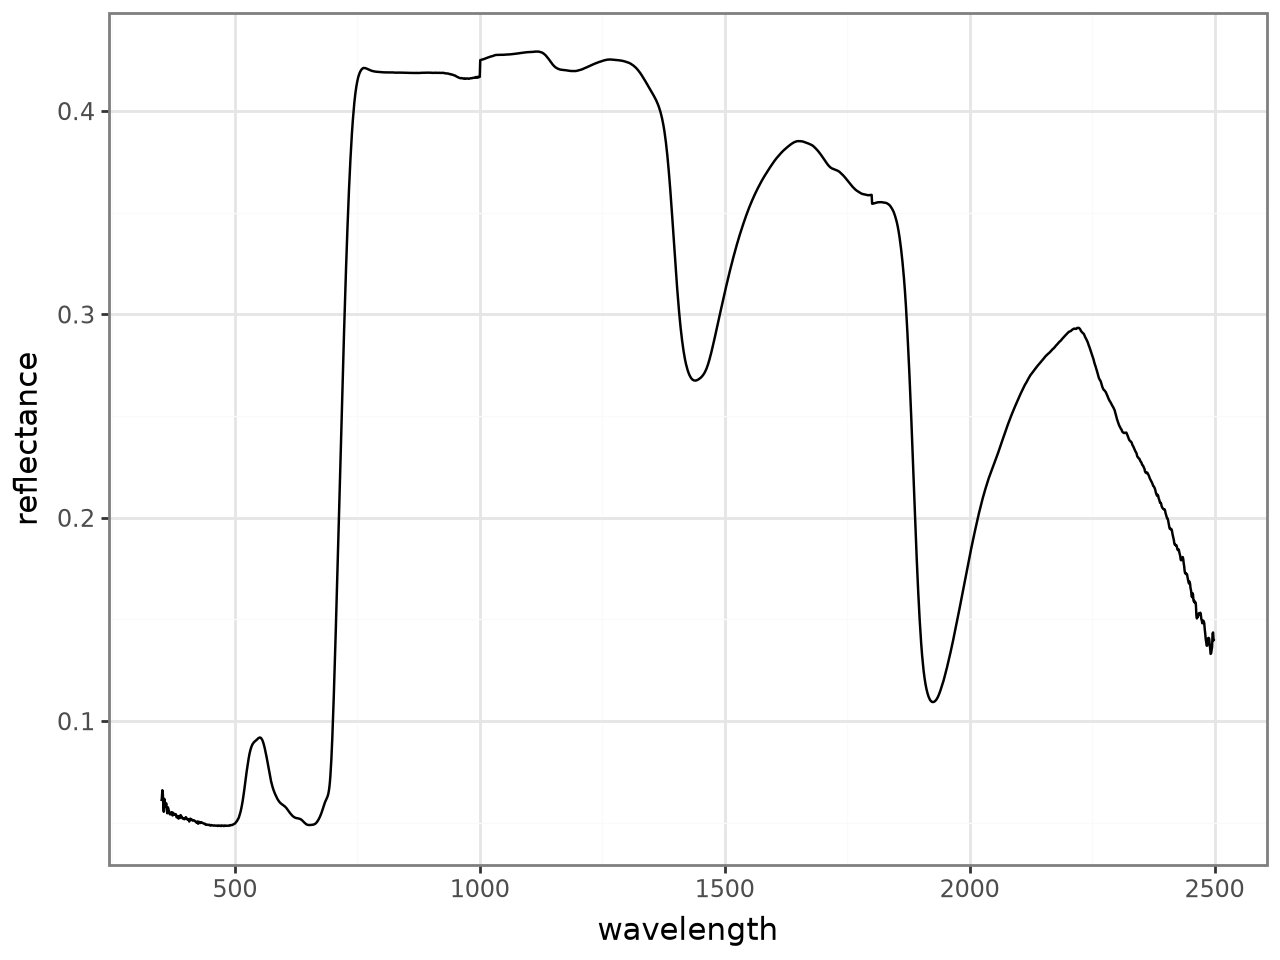

In [ ]:
ggplot(test_sp.filter(c.reflectance.is_between(0, 1))) + geom_line(
    aes(x="wavelength", y="reflectance")
)

## Load all spectra

In [ ]:
def load_spectra_folder(folder: Path, pattern="*.txt"):
    return pl.concat([load_spectra(f) for f in Path(folder).glob(pattern)])

In [105]:
def parse_filaneme(spectra_df: pl.DataFrame):
    """
    Parse the filename from the spectra DataFrame and extract relevant information.

    Parameters:
    spectra_df (pl.DataFrame): A Polars DataFrame containing the spectra data with a 'file_id' column.

    Returns:
    pl.DataFrame: A Polars DataFrame with additional columns for 'species', 'sample_id', and 'measurement_id'.
    """
    return spectra_df.with_columns(
        species=c.file_id.str.extract(r"^([a-zA-Z]+)_\d+_\d+"),
        sample_id=c.file_id.str.extract(r"^[a-zA-Z]+_(\d+)_\d+").cast(pl.Categorical),
        measurement_id=c.file_id.str.extract(r"^[a-zA-Z]+_\d+_(\d+)").cast(pl.Int64),
    ).with_columns(
        species=c.species.replace(
            {
                "beuk": "Fagus sylvatica",
                "zomereik": "Quercus robur",
                "eik": "Quercus robur",
                "esdoorn": "Acer pseudoplatanus",
                "hazelaar": "Corylus avellana",
                "lork": "Larix decidua",
                "es": "Fraxinus excelsior",
            }
        )
    )

In [106]:
leaves = load_spectra_folder(
    here("data/existing/old_spectra/gontrode_asd_23082024/leaves/txt"),
    pattern="*.asd.txt",
).collect()

In [107]:
leaves = leaves.pipe(parse_filaneme)
leaves

wavelength,reflectance,file_id,species,sample_id,measurement_id
f64,f64,str,str,cat,i64
350.0,0.070062,"""beuk_123_00001.asd""","""Fagus sylvatica""","""123""",1
351.0,0.071302,"""beuk_123_00001.asd""","""Fagus sylvatica""","""123""",1
352.0,0.069875,"""beuk_123_00001.asd""","""Fagus sylvatica""","""123""",1
353.0,0.069093,"""beuk_123_00001.asd""","""Fagus sylvatica""","""123""",1
354.0,0.06502,"""beuk_123_00001.asd""","""Fagus sylvatica""","""123""",1
…,…,…,…,…,…
2496.0,0.089121,"""esdoorn_386_00009.asd""","""Acer pseudoplatanus""","""386""",9
2497.0,0.088967,"""esdoorn_386_00009.asd""","""Acer pseudoplatanus""","""386""",9
2498.0,0.090972,"""esdoorn_386_00009.asd""","""Acer pseudoplatanus""","""386""",9


In [108]:
leaves.group_by(c.species).agg(
    n_sample=c.sample_id.n_unique(), n_measurements=c.measurement_id.n_unique()
)

species,n_sample,n_measurements
str,u32,u32
"""Corylus avellana""",3,11
"""Fraxinus excelsior""",1,10
"""Acer pseudoplatanus""",3,10
"""Quercus robur""",3,10
"""Fagus sylvatica""",3,10


In [109]:
leaves.group_by(c.species).agg(
    n_sample=c.sample_id.n_unique(), n_measurements=c.measurement_id.n_unique()
)

species,n_sample,n_measurements
str,u32,u32
"""Fagus sylvatica""",3,10
"""Quercus robur""",3,10
"""Acer pseudoplatanus""",3,10
"""Fraxinus excelsior""",1,10
"""Corylus avellana""",3,11


In [176]:
def within_between_var(spectra_df: pl.DataFrame, extra_agg: list[pl.Expr] = []) -> pl.DataFrame:
    """
    Compare within-sample and between-sample variability of reflectance measurements.
    """
    within_std =  (spectra_df.group_by(c.wavelength, c.sample_id, *extra_agg)
        .agg(
            within_sample_mean_refl=c.reflectance.mean(),
            within_sample_std_refl=c.reflectance.std(),
            within_sample_count=c.reflectance.count(),
        )
    )
    between_std  = within_std.group_by(c.wavelength, *extra_agg).agg(
        between_sample_mean_refl=c.within_sample_mean_refl.mean(),
        between_sample_std_refl=c.within_sample_mean_refl.std(),
        between_sample_count=c.within_sample_mean_refl.count()
    )
    return within_std.join(between_std, on="wavelength", how="inner")


In [178]:
within_between_var(leaves, [c.species]).group_by(c.species).agg(
        within_sample_std = c.within_sample_std_refl.mean(),
        between_sample_std = c.between_sample_std_refl.mean(),
        within_sample_count = c.within_sample_count.mean(),
        between_sample_count = c.between_sample_count.mean(),
        ratio = c.within_sample_std_refl.mean() / c.between_sample_std_refl.mean()
    )

species,within_sample_std,between_sample_std,within_sample_count,between_sample_count,ratio
str,f64,f64,f64,f64,f64
"""Fagus sylvatica""",0.01089,0.011422,9.666667,2.6,0.953484
"""Corylus avellana""",0.011881,0.011422,10.0,2.6,1.040216
"""Quercus robur""",0.012876,0.011422,10.0,2.6,1.127354
"""Fraxinus excelsior""",0.005206,0.011422,10.0,2.6,0.455848
"""Acer pseudoplatanus""",0.011839,0.011422,9.666667,2.6,1.036561


In [110]:
measurements_std_df = leaves.group_by(c.wavelength, c.sample_id, c.species).agg(
    mean_reflectance=c.reflectance.mean(),
    std_reflectance=c.reflectance.std(),
    se_reflectance=(c.reflectance.std() / c.reflectance.count().sqrt()),
)

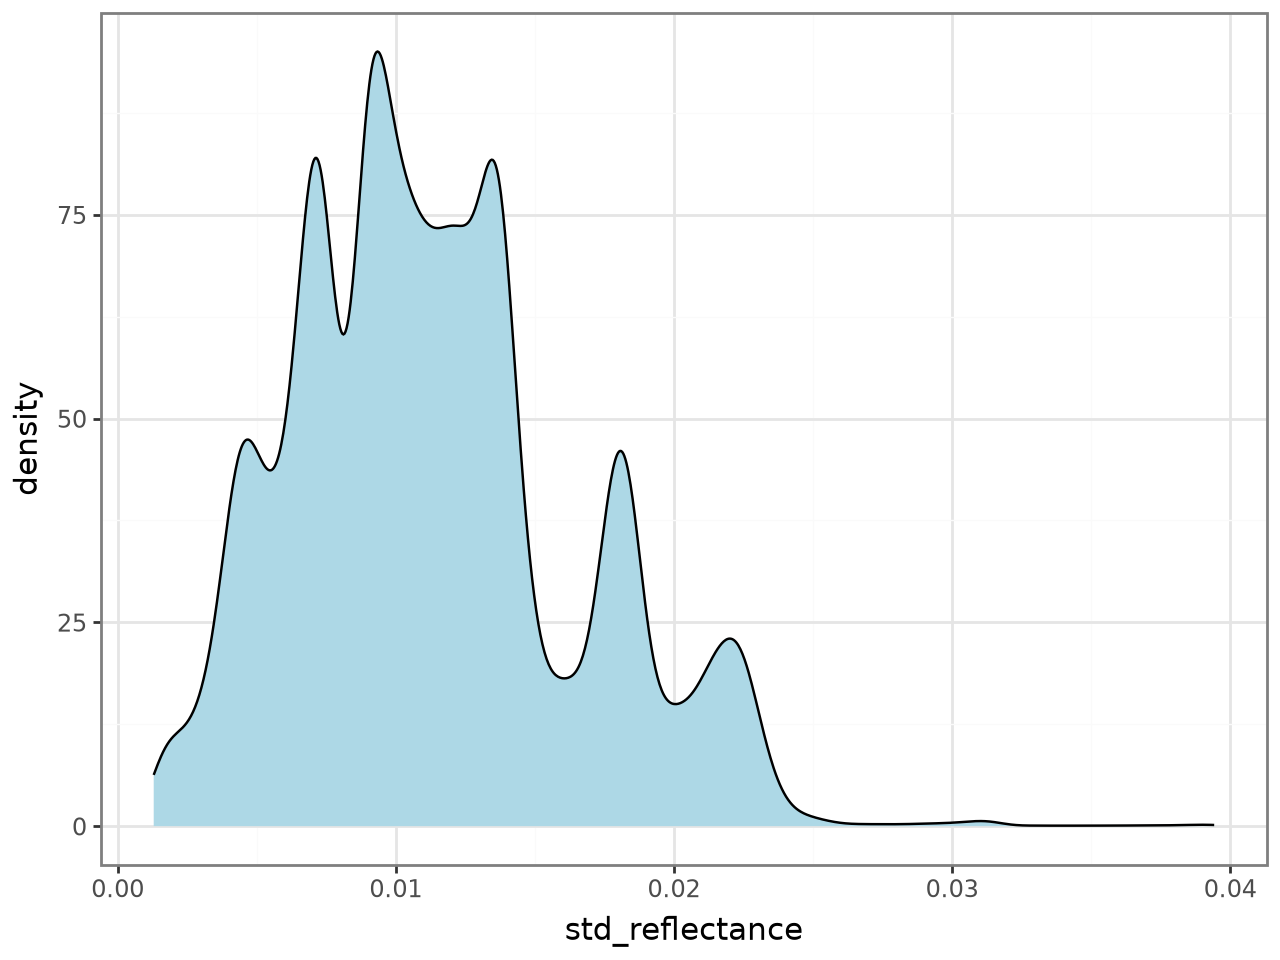

In [111]:
ggplot(measurements_std_df) + geom_density(aes("std_reflectance"), fill="lightblue")

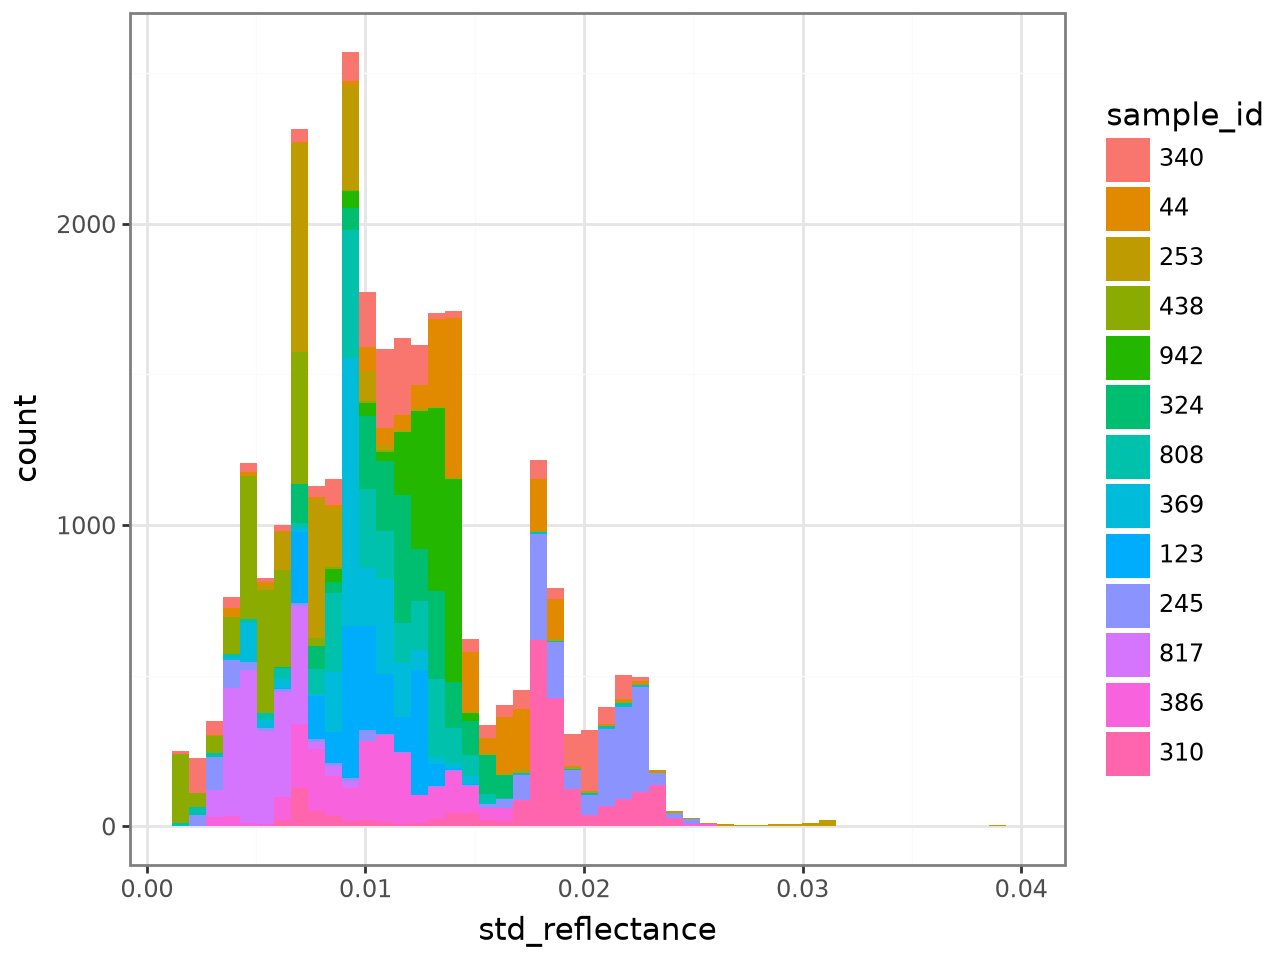

In [112]:
ggplot(measurements_std_df) + geom_histogram(
    aes("std_reflectance", fill="sample_id"), bins=50
)

In [113]:
samples_std_df = leaves.group_by(c.wavelength, c.species).agg(
    mean_reflectance=c.reflectance.mean(), std_reflectance=c.reflectance.std()
)

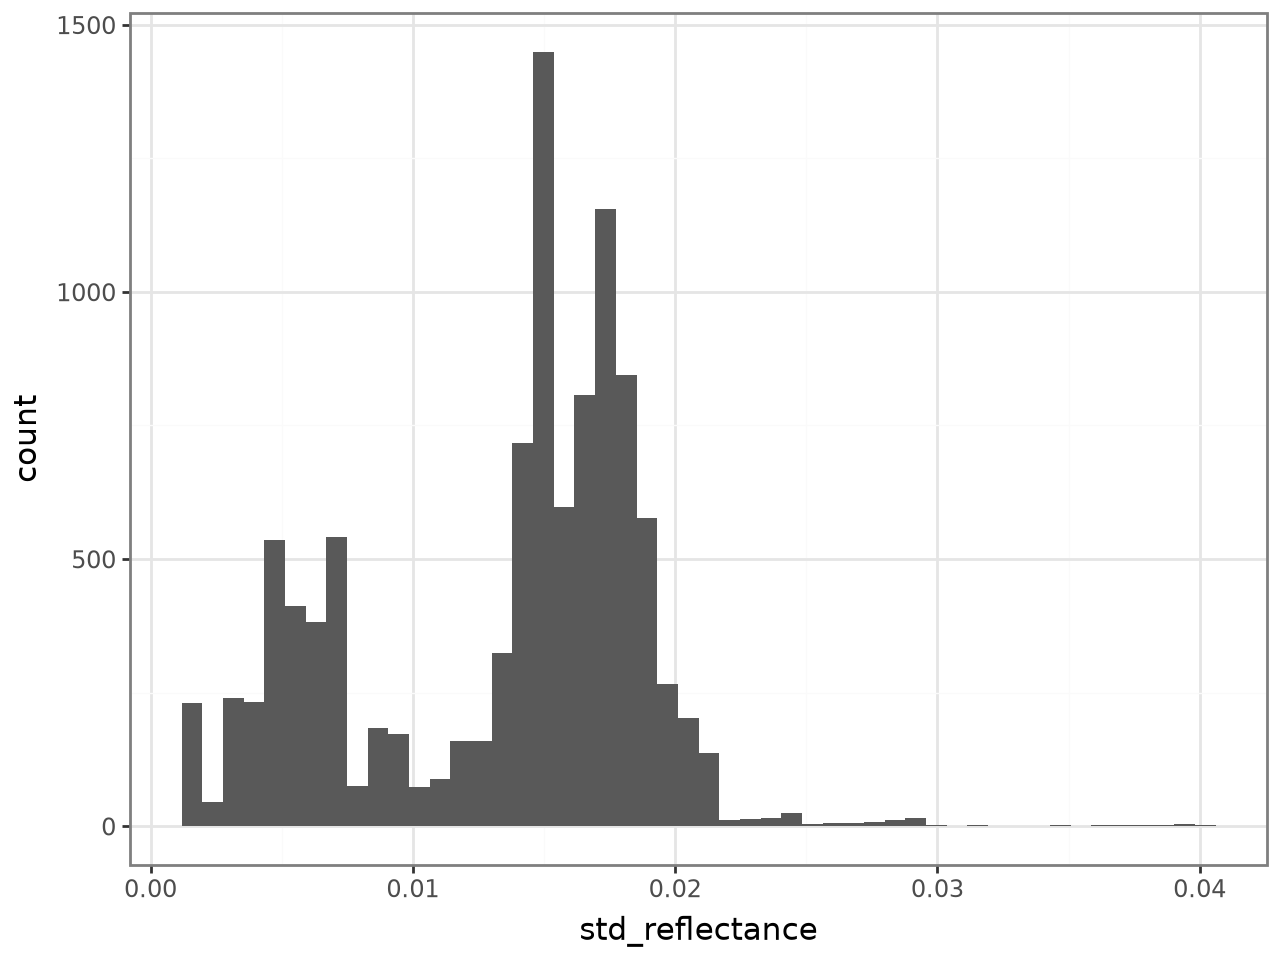

In [114]:
ggplot(samples_std_df) + geom_histogram(aes("std_reflectance"), bins=50)

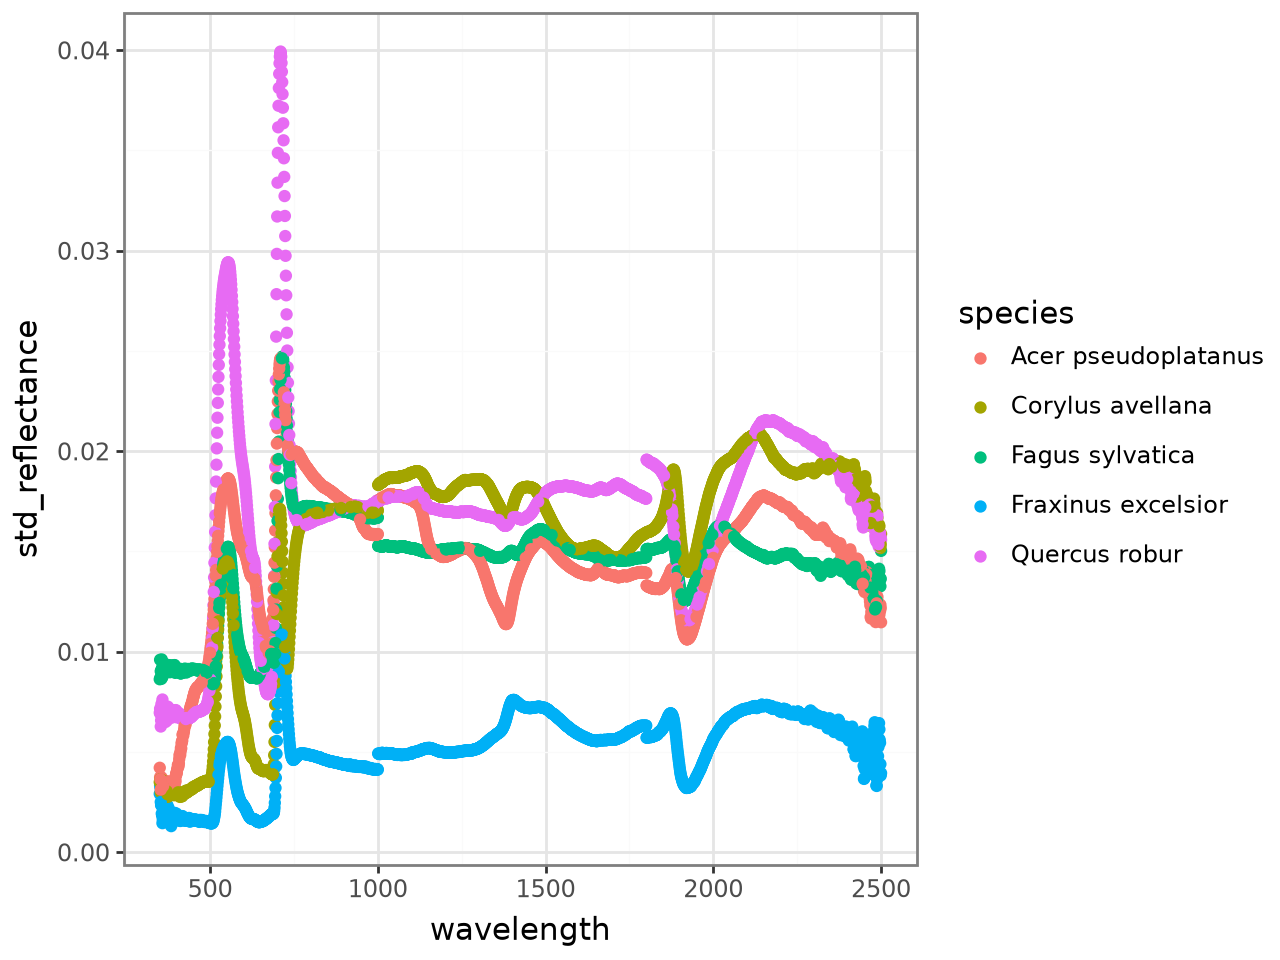

In [115]:
ggplot(samples_std_df) + geom_point(
    aes("wavelength", "std_reflectance", color="species")
)

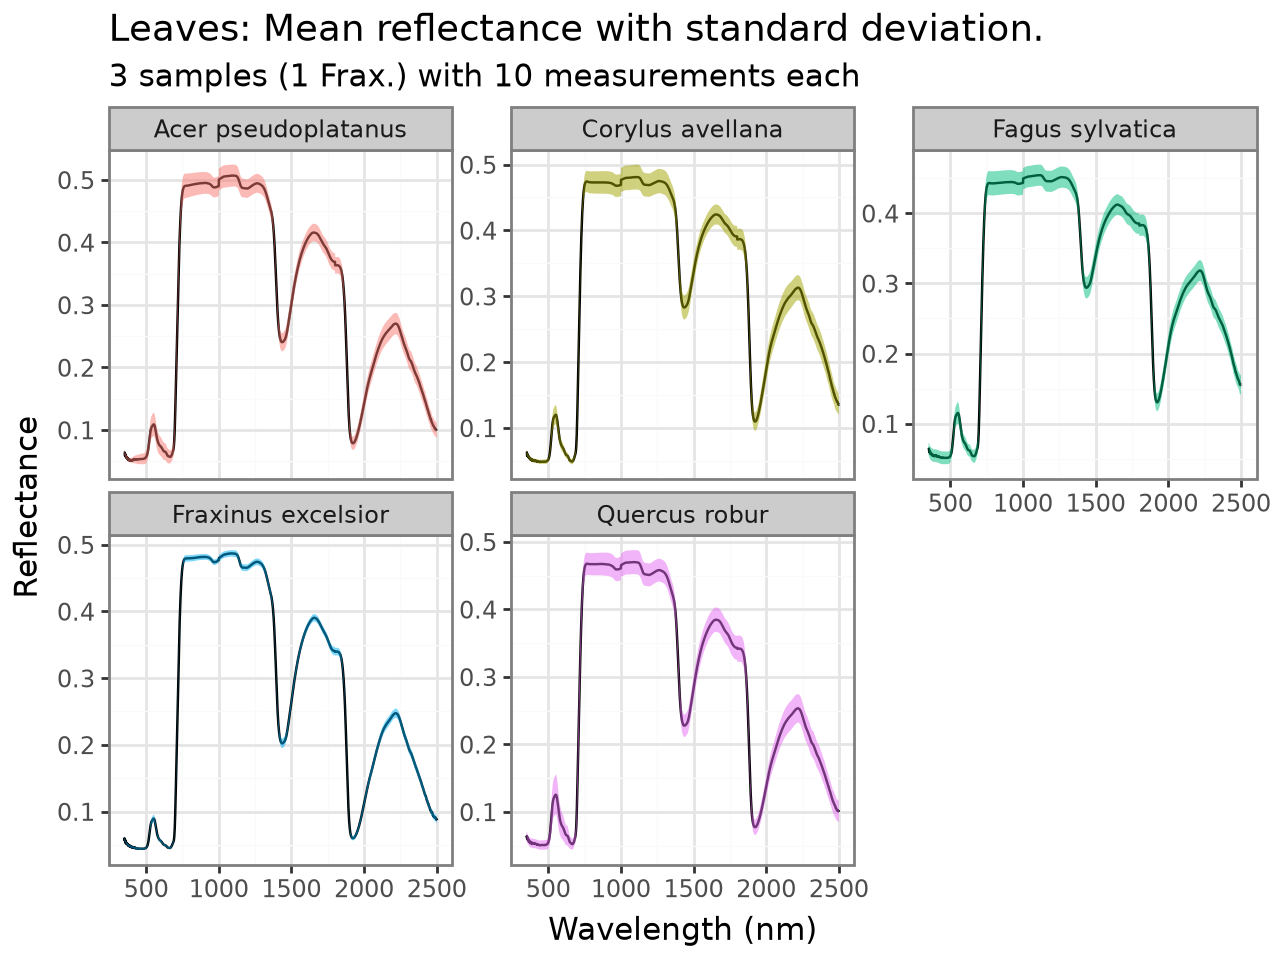

In [117]:
(
    ggplot(samples_std_df)
    + geom_line(aes("wavelength", "mean_reflectance"))
    + geom_ribbon(
        aes(
            x="wavelength",
            ymin="mean_reflectance - std_reflectance",
            ymax="mean_reflectance + std_reflectance",
            fill="species",
        ),
        alpha=0.5,
    )
    + facet_wrap("~species", scales="free_y")
    + labs(
        title="Leaves: Mean reflectance with standard deviation. ",
        subtitle="3 samples (1 Frax.) with 10 measurements each",
        x="Wavelength (nm)",
        y="Reflectance",
    )
    + theme(legend_position="none")
)

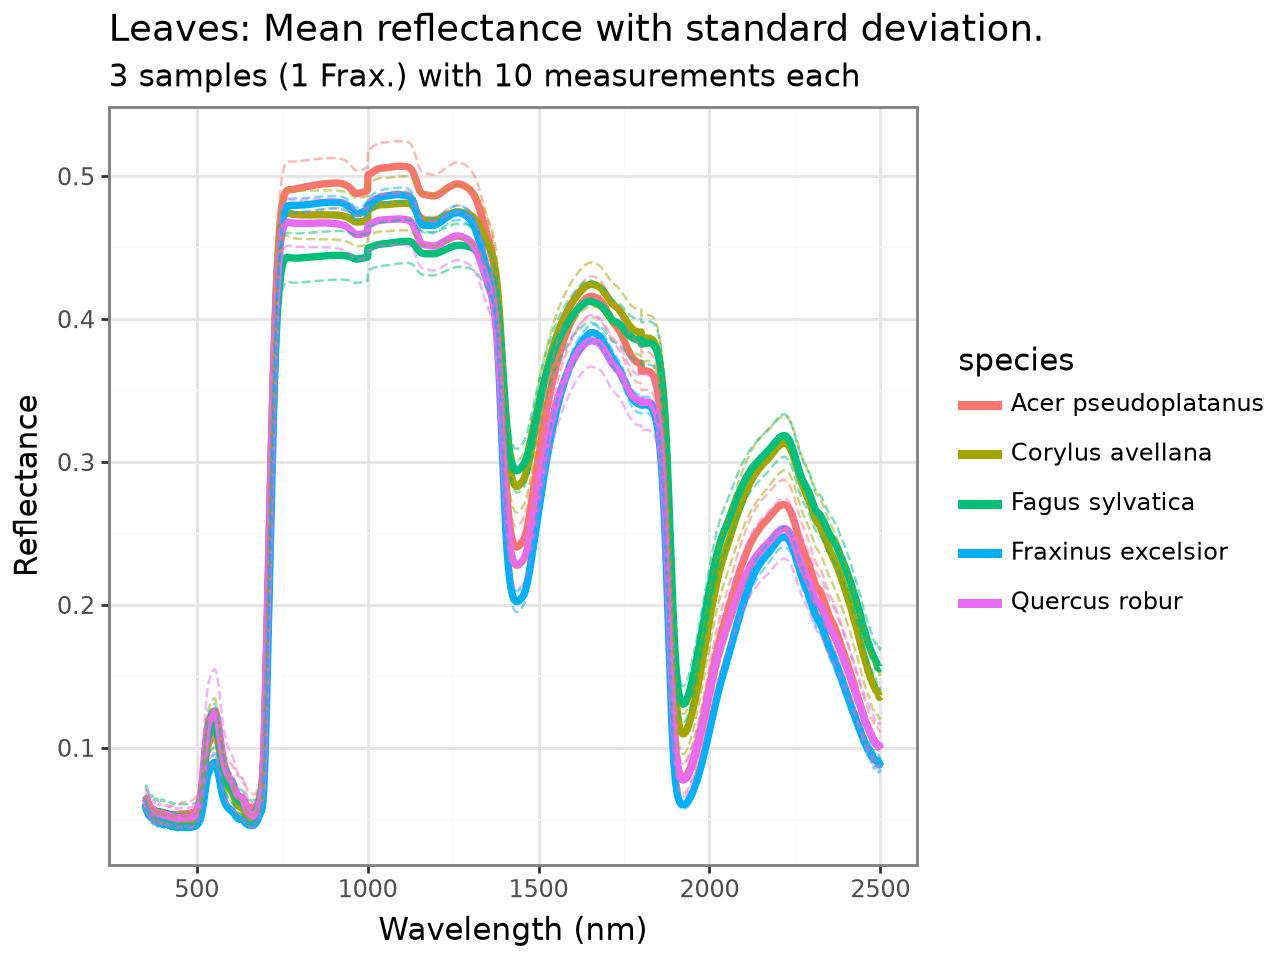

In [185]:
(
    ggplot(samples_std_df, aes("wavelength", "mean_reflectance", color="species"))
    + geom_line(size=1.5)
    + geom_line(
        aes(
            y="mean_reflectance - std_reflectance",
        ),
        alpha=0.5,
        linetype="dashed",
    )
    + geom_line(
        aes(
            y="mean_reflectance + std_reflectance",
        ),
        alpha=0.5,
        linetype="dashed",
    )
    + labs(
        title="Leaves: Mean reflectance with standard deviation. ",
        subtitle="3 samples (1 Frax.) with 10 measurements each",
        x="Wavelength (nm)",
        y="Reflectance",
    )
)

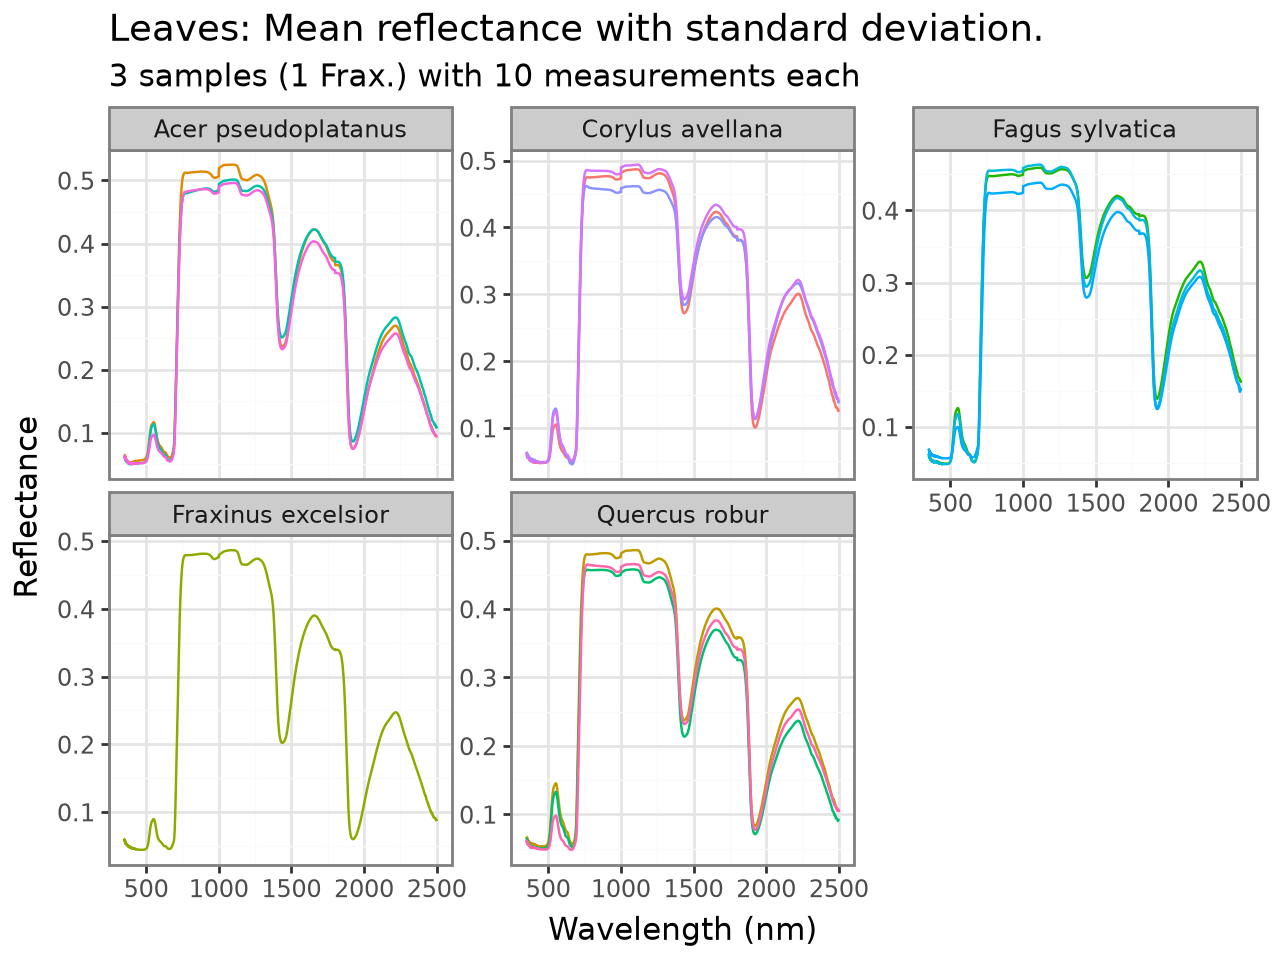

In [121]:
(
    ggplot(measurements_std_df)
    + geom_line(aes("wavelength", "mean_reflectance", color="sample_id"))
    + facet_wrap("~species", scales="free_y")
    + labs(
        title="Leaves: Mean reflectance with standard deviation. ",
        subtitle="3 samples (1 Frax.) with 10 measurements each",
        x="Wavelength (nm)",
        y="Reflectance",
    )
    + theme(legend_position="none")
)

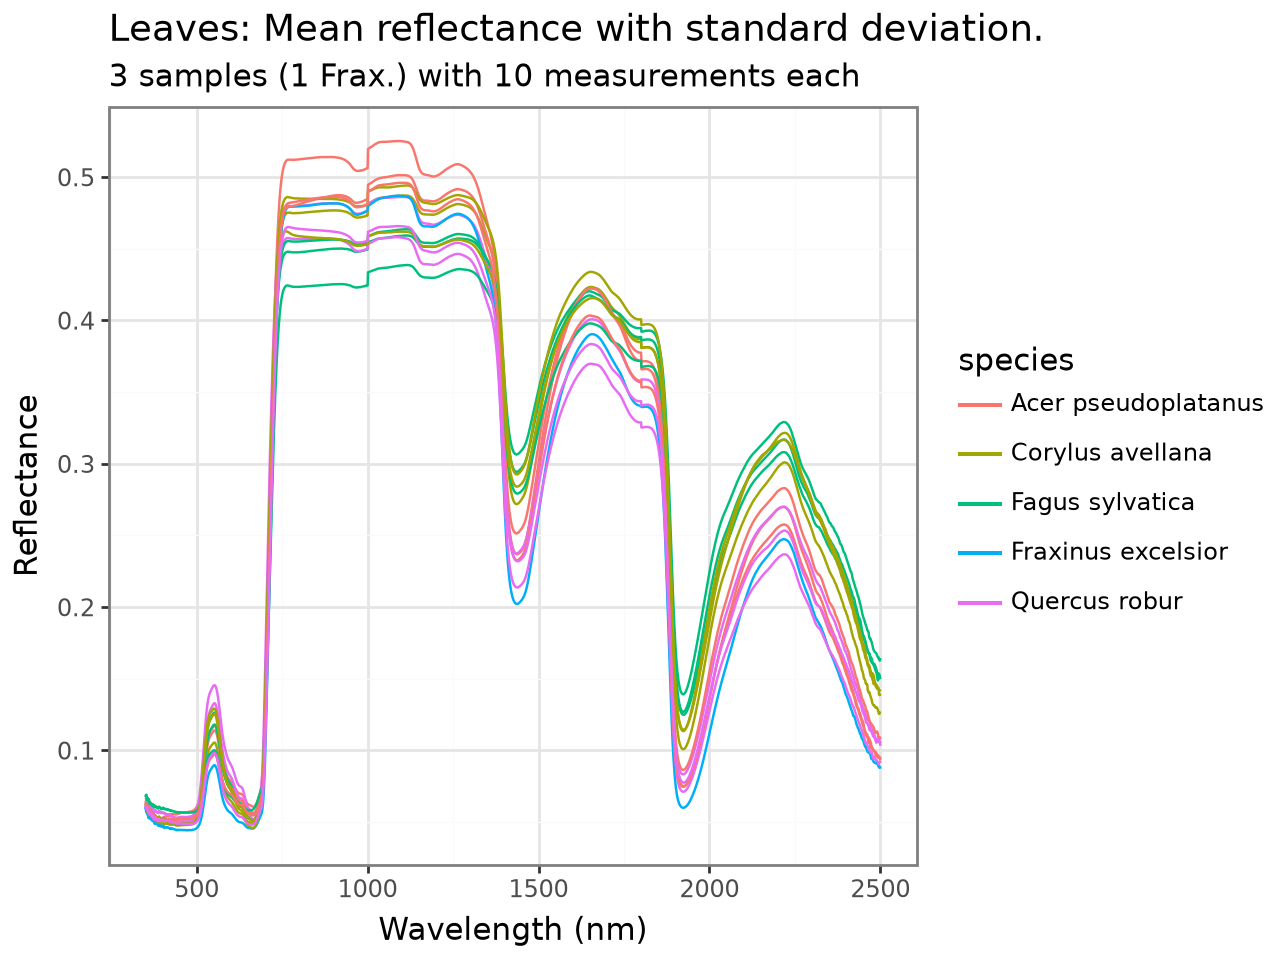

In [124]:
(
    ggplot(measurements_std_df)
    + geom_line(aes("wavelength", "mean_reflectance", color="species", group="sample_id"))
    + labs(
        title="Leaves: Mean reflectance with standard deviation. ",
        subtitle="3 samples (1 Frax.) with 10 measurements each",
        x="Wavelength (nm)",
        y="Reflectance",
    )
)

## Bark

In [131]:
bark = load_spectra_folder(
    here("data/existing/old_spectra/gontrode_asd_23082024/bark/txt"),
    pattern="*.asd.txt",
).collect().pipe(parse_filaneme)

In [132]:
bark

wavelength,reflectance,file_id,species,sample_id,measurement_id
f64,f64,str,str,cat,i64
350.0,0.105101,"""hazelaar_927_00002.asd""","""Corylus avellana""","""927""",2
351.0,0.101651,"""hazelaar_927_00002.asd""","""Corylus avellana""","""927""",2
352.0,0.100584,"""hazelaar_927_00002.asd""","""Corylus avellana""","""927""",2
353.0,0.102349,"""hazelaar_927_00002.asd""","""Corylus avellana""","""927""",2
354.0,0.101171,"""hazelaar_927_00002.asd""","""Corylus avellana""","""927""",2
…,…,…,…,…,…
2496.0,0.20065,"""beuk_66_00001.asd""","""Fagus sylvatica""","""66""",1
2497.0,0.201702,"""beuk_66_00001.asd""","""Fagus sylvatica""","""66""",1
2498.0,0.203945,"""beuk_66_00001.asd""","""Fagus sylvatica""","""66""",1


In [133]:
bark_samples_std_df = bark.group_by(c.wavelength, c.species).agg(
    mean_reflectance=c.reflectance.mean(), std_reflectance=c.reflectance.std()
)

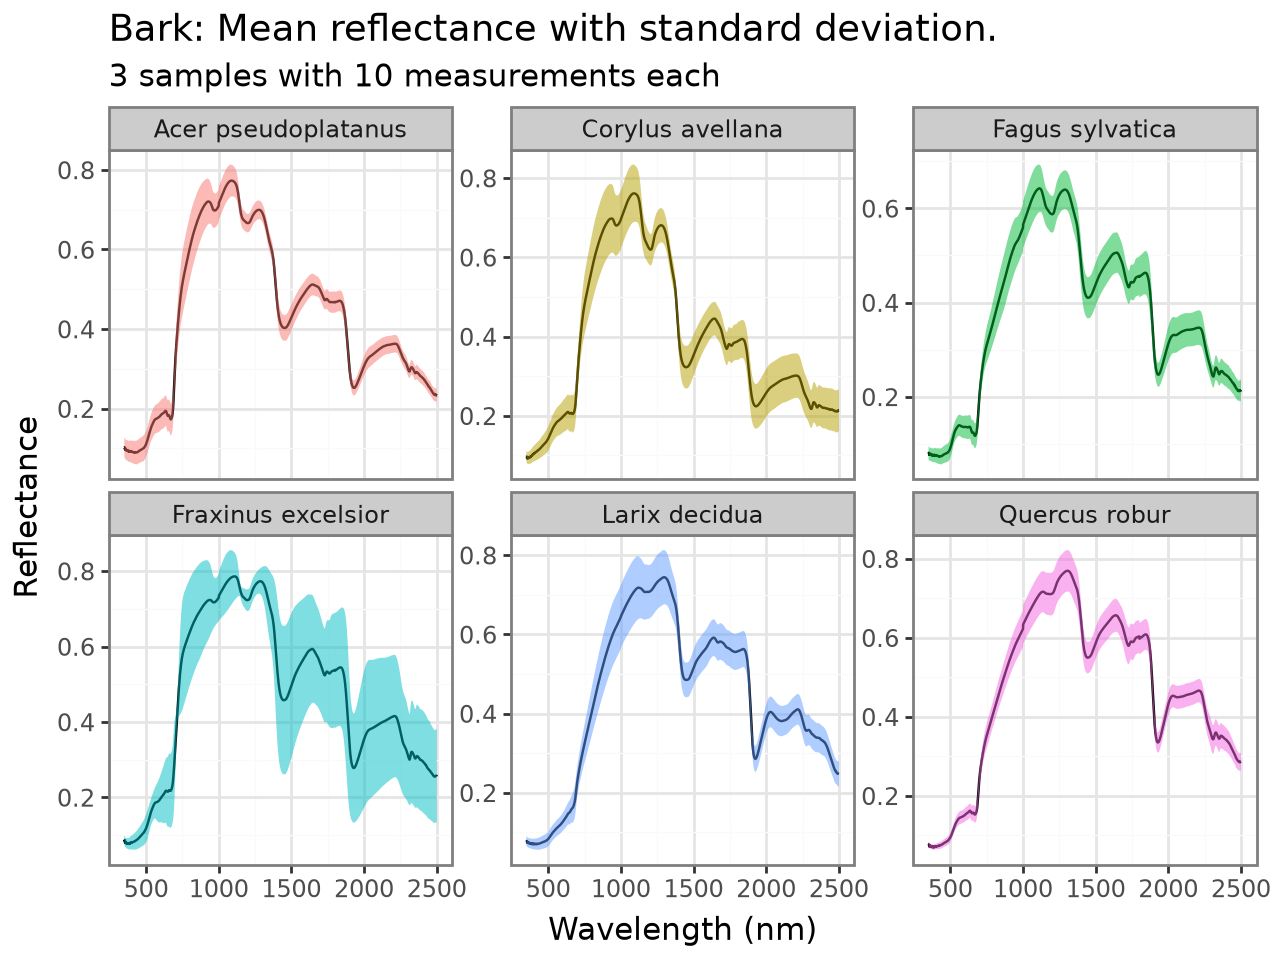

In [191]:
(
    ggplot(bark_samples_std_df.filter(c.species != "es"))
    + geom_line(aes("wavelength", "mean_reflectance"))
    + geom_ribbon(
        aes(
            x="wavelength",
            ymin="mean_reflectance - std_reflectance",
            ymax="mean_reflectance + std_reflectance",
            fill="species",
        ),
        alpha=0.5,
    )
    + facet_wrap("~species", scales="free_y")
    + labs(
        title="Bark: Mean reflectance with standard deviation. ",
        subtitle="3 samples with 10 measurements each",
        x="Wavelength (nm)",
        y="Reflectance",
    )
    + theme(legend_position="none")
)

In [179]:
within_between_var(bark, [c.species]).group_by(c.species).agg(
        within_sample_std = c.within_sample_std_refl.mean(),
        between_sample_std = c.between_sample_std_refl.mean(),
        within_sample_count = c.within_sample_count.mean(),
        between_sample_count = c.between_sample_count.mean(),
        ratio = c.within_sample_std_refl.mean() / c.between_sample_std_refl.mean()
    )

species,within_sample_std,between_sample_std,within_sample_count,between_sample_count,ratio
str,f64,f64,f64,f64,f64
"""Larix decidua""",0.040616,0.047435,5.0,3.166667,0.856248
"""Quercus robur""",0.029238,0.047435,5.0,3.166667,0.616387
"""Fagus sylvatica""",0.022237,0.047435,5.0,3.166667,0.468792
"""Fraxinus excelsior""",0.019151,0.047435,5.0,3.166667,0.403726
"""Acer pseudoplatanus""",0.024067,0.047435,5.0,3.166667,0.507363
"""Corylus avellana""",0.039963,0.047435,5.0,3.166667,0.842493


## Soil

In [153]:
def parse_soil_filename(spectra_df: pl.DataFrame):
    """
    Parse the filename from the soil spectra DataFrame and extract relevant information.

    Parameters:
    spectra_df (pl.DataFrame): A Polars DataFrame containing the soil spectra data with a 'file_id' column.

    Returns:
    pl.DataFrame: A Polars DataFrame with additional columns for 'soil_type', 'sample_id', and 'measurement_id'.
    """
    return spectra_df.with_columns(
        sample_id=c.file_id.str.extract(r"^soil_(\d+_\d+)"),
        measurement_id=c.file_id.str.extract(r"(\d+).asd$").cast(pl.Int64),
    )

In [154]:
soil = load_spectra_folder(here("data/existing/old_spectra/gontrode_asd_25032024/soil/processed/"), "soil_*.asd.txt").collect().pipe(parse_soil_filename)

In [155]:
soil

wavelength,reflectance,file_id,sample_id,measurement_id
f64,f64,str,str,i64
350.0,0.017401,"""soil_1_5_00000.asd""","""1_5""",0
351.0,0.021145,"""soil_1_5_00000.asd""","""1_5""",0
352.0,0.022335,"""soil_1_5_00000.asd""","""1_5""",0
353.0,0.019095,"""soil_1_5_00000.asd""","""1_5""",0
354.0,0.019914,"""soil_1_5_00000.asd""","""1_5""",0
…,…,…,…,…
2496.0,null,"""soil_1_6_00000.asd""","""1_6""",0
2497.0,null,"""soil_1_6_00000.asd""","""1_6""",0
2498.0,null,"""soil_1_6_00000.asd""","""1_6""",0


In [ ]:
soil_std = soil.group_by(c.wavelength).agg(
    mean_reflectance=c.reflectance.mean(),
    std_reflectance=c.reflectance.std(),
    se_reflectance=(c.reflectance.std() / c.reflectance.count().sqrt()),
)

soil_meas_std = soil.group_by(c.wavelength, c.sample_id).agg(
    mean_reflectance=c.reflectance.mean(),
    std_reflectance=c.reflectance.std(),
    se_reflectance=(c.reflectance.std() / c.reflectance.count().sqrt()),
)

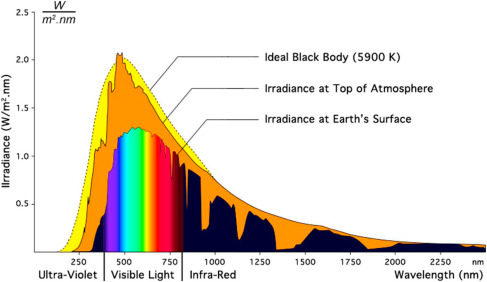

https://www.sciencedirect.com/topics/physics-and-astronomy/solar-spectra

The measurements are very noisy for the bands with strong abosrption from the atmosphere.

Can think of some smarter idea to smooth that section of the spectra.

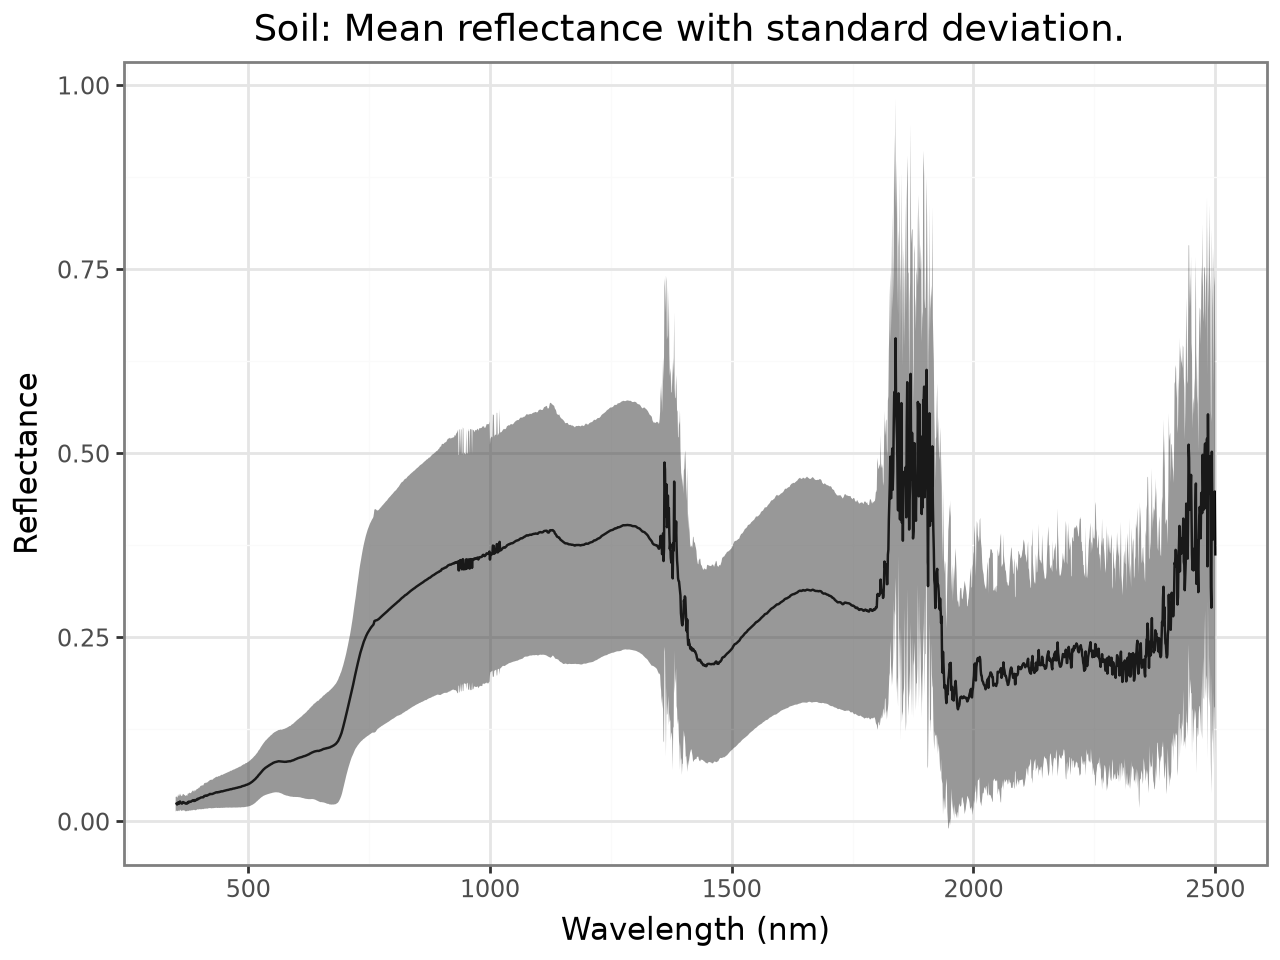

In [159]:
ggplot(soil_std) + geom_line(aes("wavelength", "mean_reflectance")) + geom_ribbon(
    aes(
        x="wavelength",
        ymin="mean_reflectance - std_reflectance",
        ymax="mean_reflectance + std_reflectance",
    ),
    alpha=0.5,
) + labs(
    title="Soil: Mean reflectance with standard deviation. ",
    x="Wavelength (nm)",
    y="Reflectance",
)

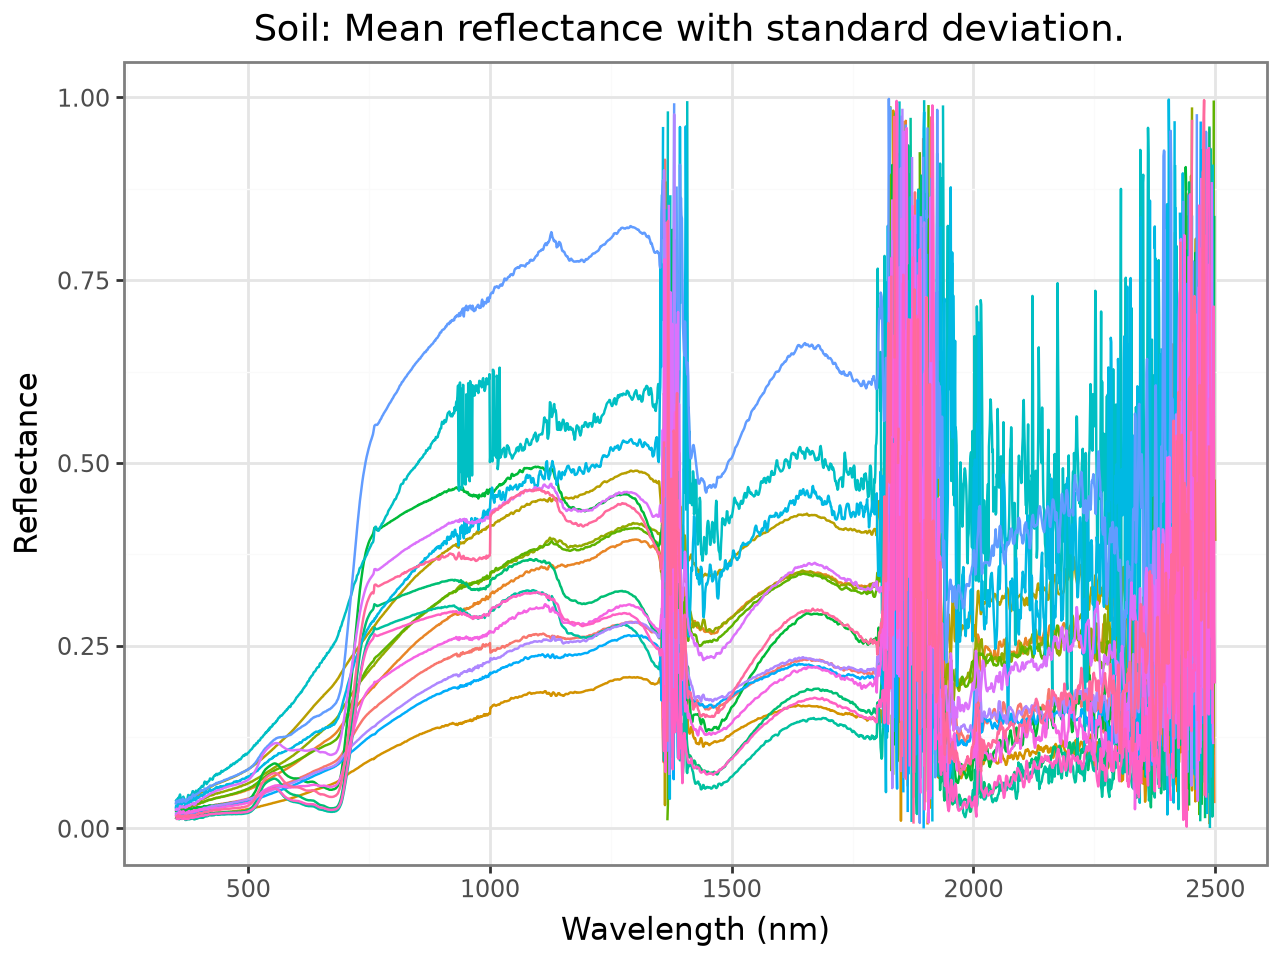

In [184]:
ggplot(soil_meas_std) + geom_line(aes("wavelength", "mean_reflectance", color="sample_id")) + labs(
    title="Soil: Mean reflectance with standard deviation. ",
    x="Wavelength (nm)",
    y="Reflectance",
) + theme(legend_position="none")

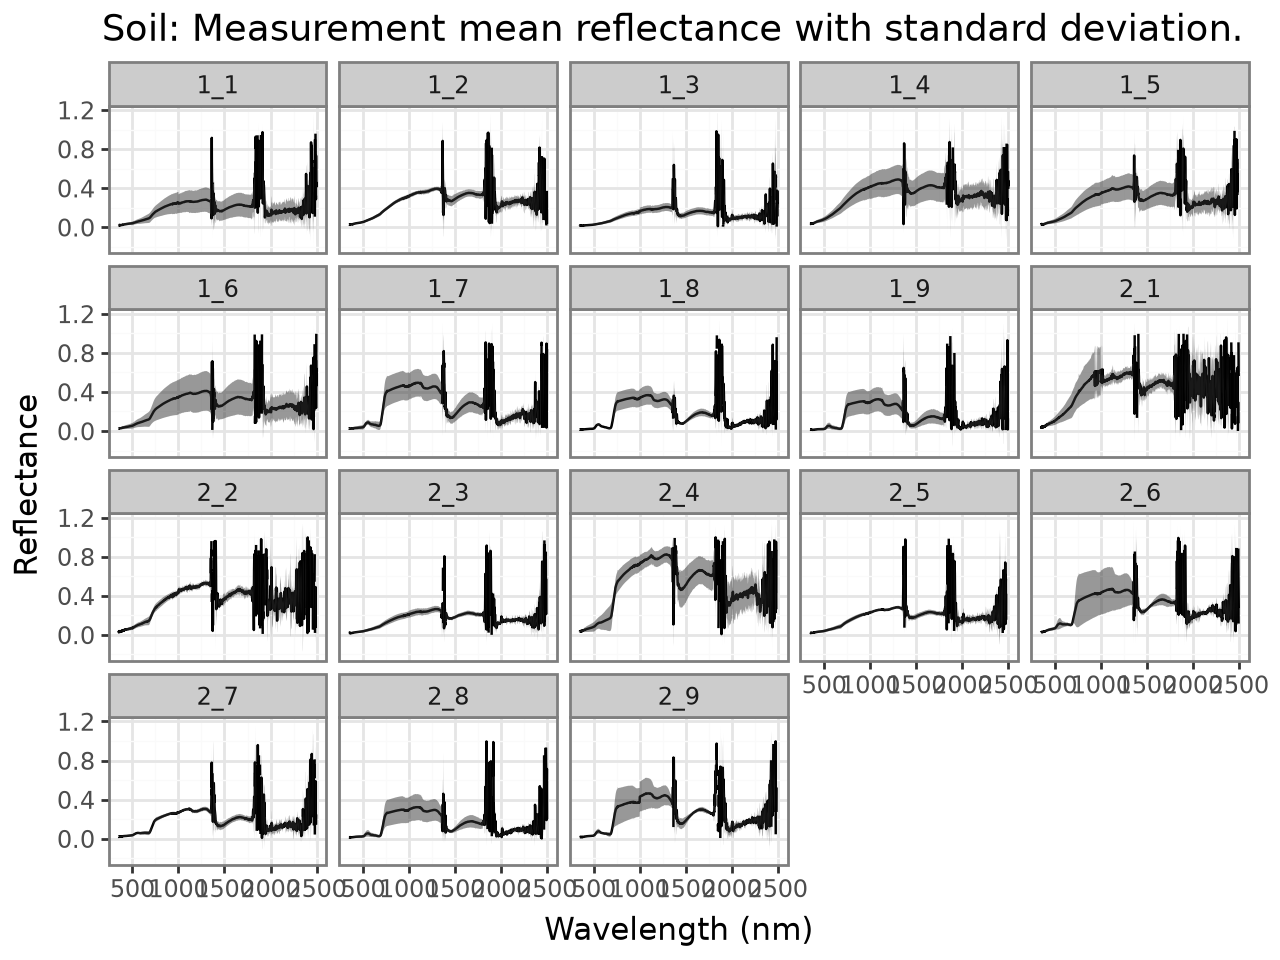

In [182]:
ggplot(soil_meas_std) + geom_line(aes("wavelength", "mean_reflectance")) + geom_ribbon(
    aes(
        x="wavelength",
        ymin="mean_reflectance - std_reflectance",
        ymax="mean_reflectance + std_reflectance",
    ),
    alpha=0.5,
) + labs(
    title="Soil: Measurement mean reflectance with standard deviation. ",
    x="Wavelength (nm)",
    y="Reflectance",
) + facet_wrap("~sample_id")

/home/simone/dev/phenontrode/.pixi/envs/default/lib/python3.15/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 6 rows containing missing values.


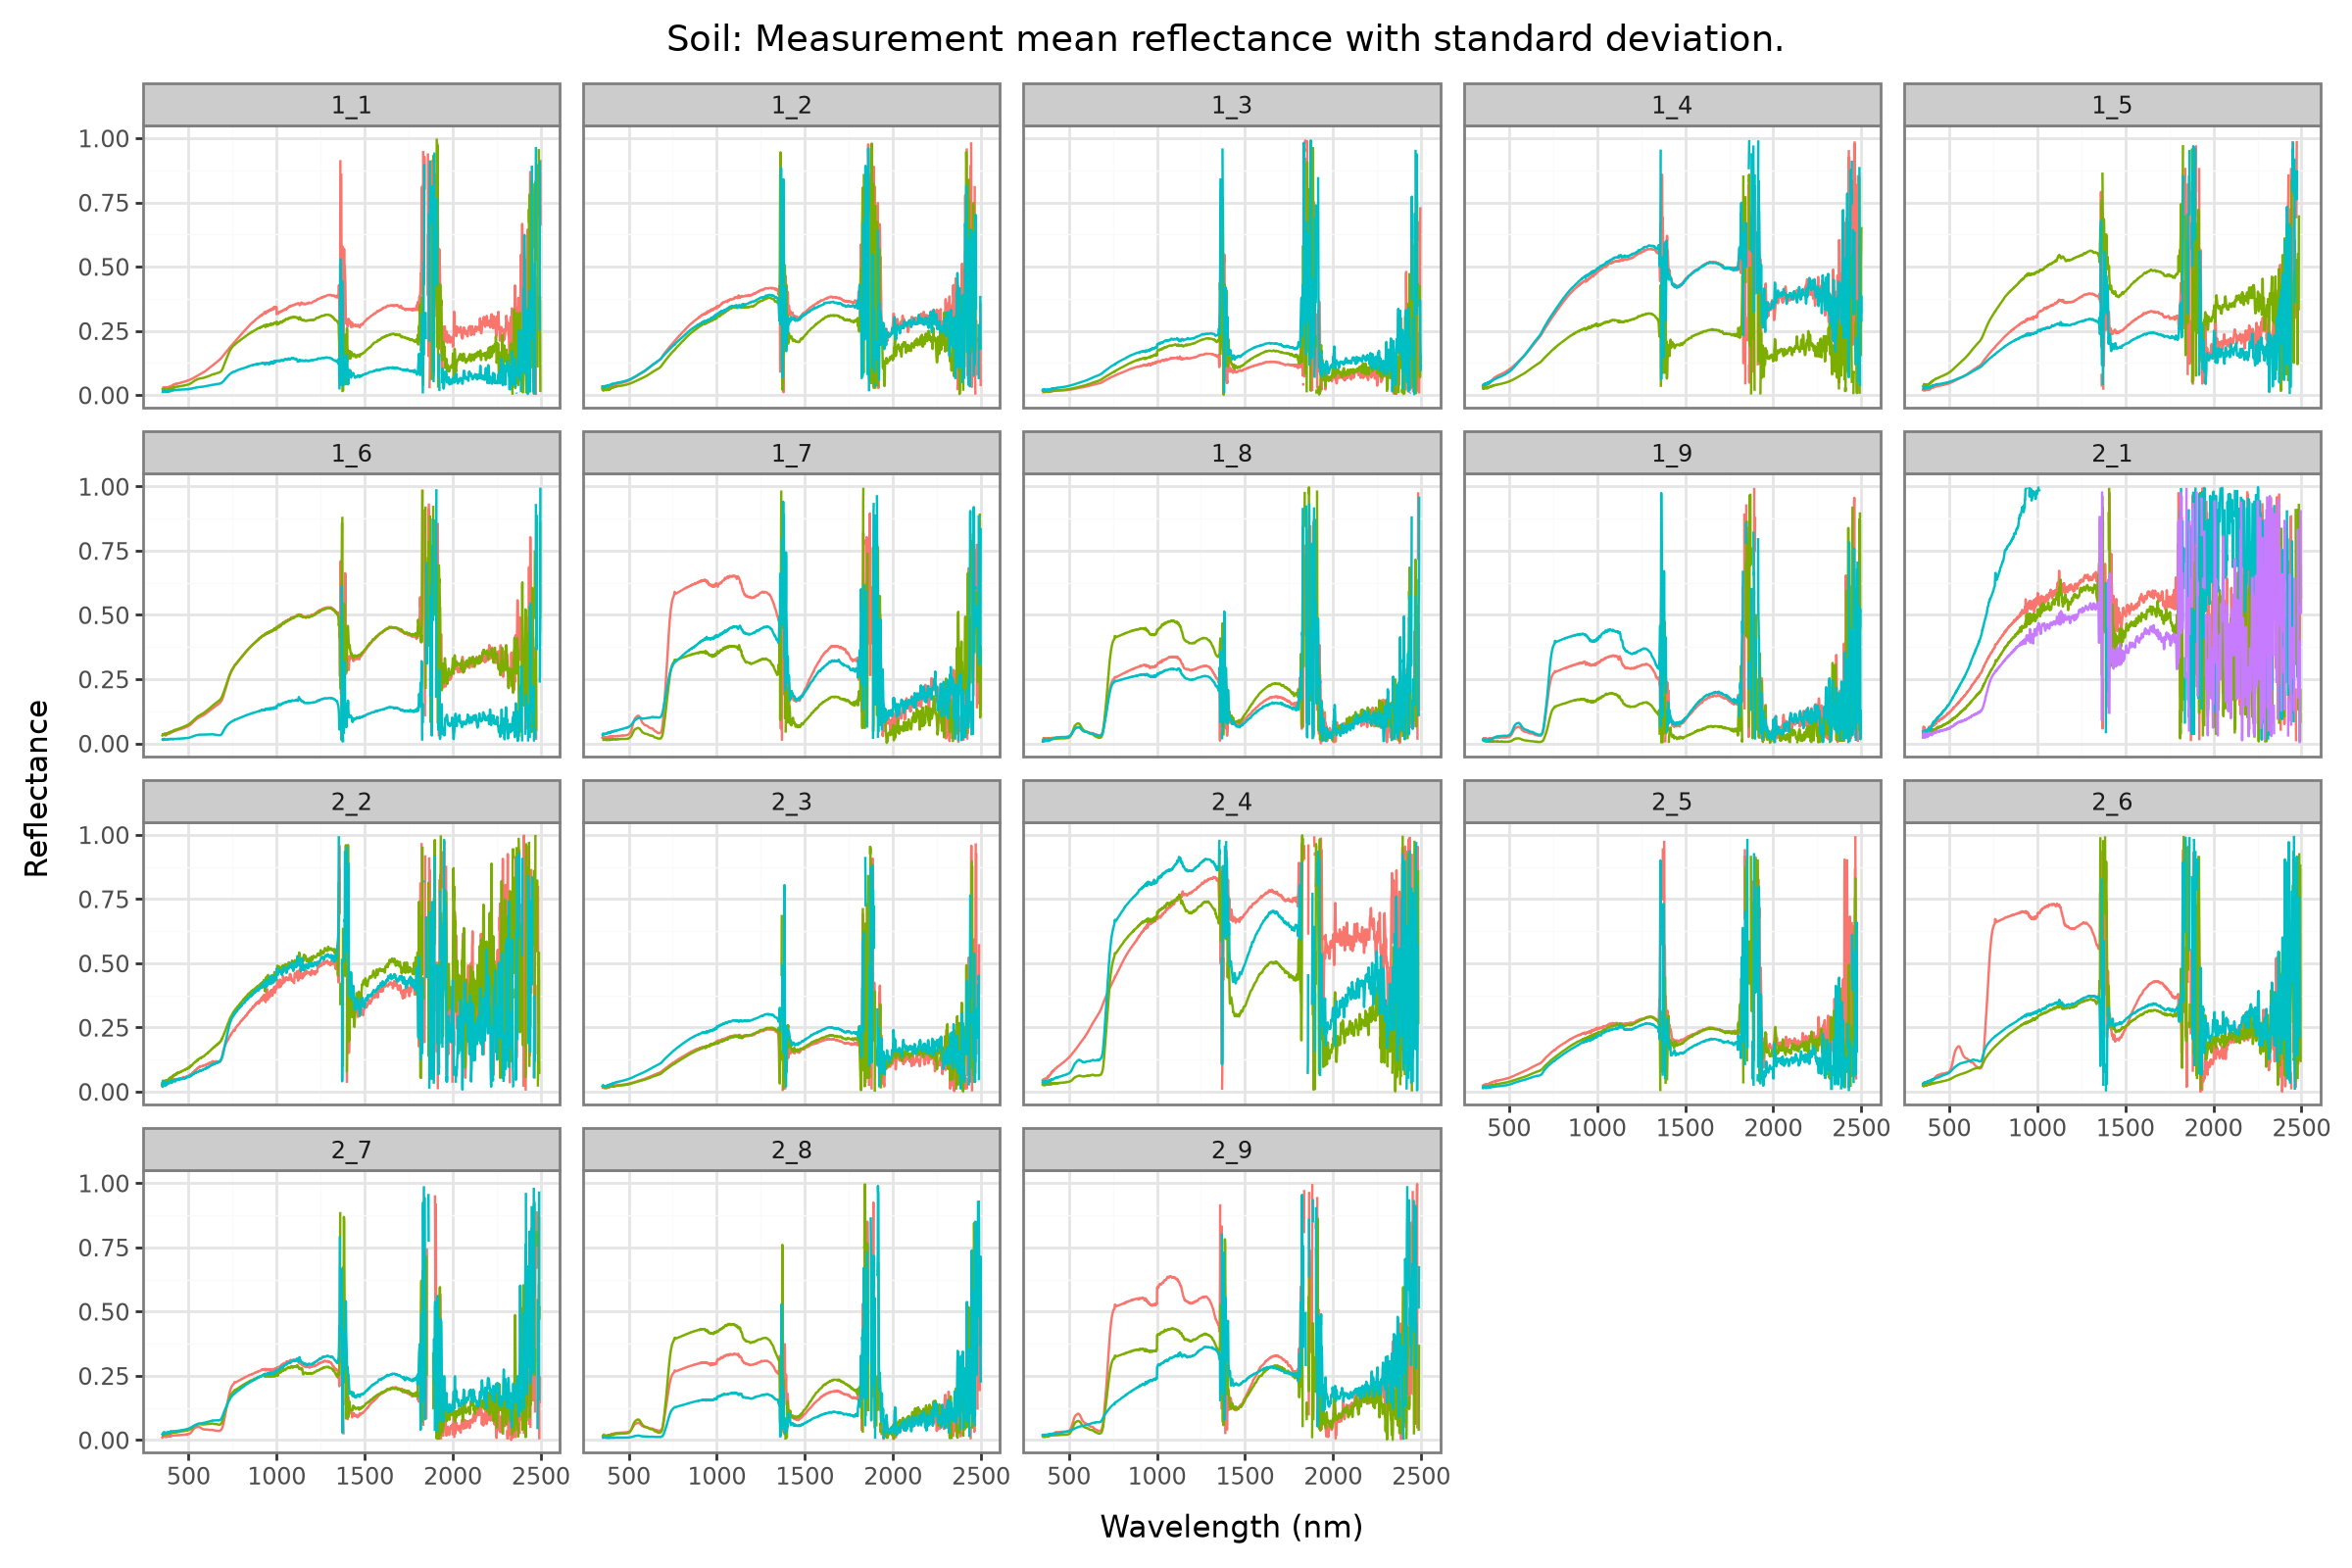

In [190]:
ggplot(soil) + geom_line(aes("wavelength", "reflectance", color="factor(measurement_id)")) + labs(
    title="Soil: Measurement mean reflectance with standard deviation. ",
    x="Wavelength (nm)",
    y="Reflectance",
) + facet_wrap("~sample_id") + theme(
    legend_position="none",
    figure_size=(12, 8)
)